Spotify Dataset - Machine Learning (Modelado)

Lucas Concha
Natalia Hormazabal
Martin Villarroel

Este notebook continúa `notebooks/01_EDA_Preparacion.ipynb`. **Ejecutar desde la carpeta `notebooks/`**: lee `../data_procesado/spotify_tracks_clean.csv` y `../data/`, guarda los gráficos en `../images/` y guarda en `../models/` los modelos entrenados (`.joblib`) y `parametros.json`.

# Modelado (EP2)

Se parte desde `data_procesado/spotify_tracks_clean.csv` (EP1). En esta sección se corrige el escalado
(ajustándolo solo con entrenamiento), se eliminan las filas con compás inválido, se **particiona agrupando por
artista + nombre de la canción**, se entrenan y comparan dos modelos supervisados contra un baseline justo
(mediana por género), se aplica una técnica no supervisada (K-Means) y se evalúan los KPIs definidos en el README.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import joblib, json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_squared_error, mean_absolute_error, silhouette_score, adjusted_rand_score,
                             precision_recall_curve, recall_score, precision_score, f1_score,
                             average_precision_score, roc_auc_score, davies_bouldin_score)

sns.set_theme(style="whitegrid")
SEMILLA = 42

df = pd.read_csv("../data_procesado/spotify_tracks_clean.csv")

audio_cols = ["danceability", "energy", "loudness", "speechiness",
              "acousticness", "instrumentalness", "liveness", "valence", "tempo"]

TARGET = "popularity"
COL_ID = "track_id"
COLS_TEXTO = ["artists", "album_name", "track_name"]
COLS_GENERO = [c for c in df.columns if c.startswith("genre_")]
FEATURES = audio_cols + ["duration_ms", "explicit", "key", "mode", "time_signature"] + COLS_GENERO

print("Filas:", df.shape[0], "| Predictoras:", len(FEATURES))

Filas: 113549 | Predictoras: 127


## Compás fuera de rango (`time_signature` 0 y 1): se eliminan

Según la documentación de la API de Spotify, `time_signature` va de 3 a 7. Las 1.130 filas con
valor 0 o 1 están fuera de ese rango, a diferencia de otras anomalías del EP1 (como el tempo = 0) que podían
corresponder a audio real. Siguiendo el mismo criterio usado con el único registro nulo del EP1, se eliminan antes
de modelar en vez de imputarse. (Las canciones con `tempo = 0` casi siempre traen también compás inválido, así que
este filtro las retira también.)

In [2]:
filas_antes = df.shape[0]
df = df[df["time_signature"].between(3, 7)].reset_index(drop=True)
print(f"Filas eliminadas por compás inválido: {filas_antes - df.shape[0]}")
print(f"Filas restantes: {df.shape[0]}")
print("Canciones con tempo = 0 que quedan:", (df["tempo"] == 0).sum())

Filas eliminadas por compás inválido: 1130
Filas restantes: 112419
Canciones con tempo = 0 que quedan: 0


## Partición de datos (`GroupShuffleSplit`) agrupando por artista + nombre

En el EP1 se detectó que una misma canción aparece en varios géneros con el mismo `track_id`. Pero **agrupar solo por
`track_id` no basta**: la misma canción también puede venir con `track_id` distintos (single, álbum, recopilación) y
con audio casi idéntico y popularidad parecida. Si esas copias caen una en entrenamiento y otra en prueba, el modelo
«ve» la canción antes de evaluarla (fuga de información).

Por eso la clave de agrupación es **artista + nombre de la canción** (en minúsculas y sin espacios sobrantes).
Abajo se muestra cuánta fuga queda si se agrupara solo por `track_id`.

In [3]:
df["grupo_cancion"] = (df["artists"].str.lower().str.strip() + " || " + df["track_name"].str.lower().str.strip())

print("track_id distintos:", df[COL_ID].nunique())
print("Canciones distintas (artista + nombre):", df["grupo_cancion"].nunique())
ids_por_cancion = df.groupby("grupo_cancion")[COL_ID].nunique()
print("Canciones con más de un track_id:", (ids_por_cancion > 1).sum())

# ¿Los distintos track_id de una misma canción suenan igual? (rango dentro de la canción, escala 0-1)
una_fila_por_id = df.drop_duplicates(COL_ID)
multi = una_fila_por_id[una_fila_por_id.groupby("grupo_cancion")[COL_ID].transform("nunique") > 1]
rango_dance = multi.groupby("grupo_cancion")["danceability"].agg(lambda s: s.max() - s.min())
print(f"Canciones con varios track_id y danceability casi igual (rango <= 0,05): {(rango_dance <= 0.05).mean()*100:.1f}%")

track_id distintos: 88732
Canciones distintas (artista + nombre): 80286
Canciones con más de un track_id: 4698
Canciones con varios track_id y danceability casi igual (rango <= 0,05): 90.8%


In [4]:
X = df[FEATURES].copy()
y = df[TARGET].copy()
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)

# (a) Lo que pasaría agrupando SOLO por track_id (solo para medir la fuga; no se usa)
tr_a, te_a = next(gss.split(X, y, groups=df[COL_ID]))
compartidas = set(df["grupo_cancion"].iloc[tr_a]) & set(df["grupo_cancion"].iloc[te_a])
filas_afectadas = df["grupo_cancion"].iloc[te_a].isin(compartidas).sum()
print(f"Agrupando solo por track_id: {len(compartidas)} canciones quedan en train y test a la vez "
      f"({filas_afectadas} filas de test, {filas_afectadas/len(te_a)*100:.1f}%)")

# (b) Partición final: agrupada por artista + nombre
train_idx, test_idx = next(gss.split(X, y, groups=df["grupo_cancion"]))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
genero_train = df.iloc[train_idx]["track_genre_label"]
genero_test = df.iloc[test_idx]["track_genre_label"]
grupos_train = df.iloc[train_idx]["grupo_cancion"].values

assert len(set(df.iloc[train_idx]["grupo_cancion"]) & set(df.iloc[test_idx]["grupo_cancion"])) == 0, "Fuga por artista + nombre"
assert len(set(df.iloc[train_idx][COL_ID]) & set(df.iloc[test_idx][COL_ID])) == 0, "Fuga por track_id"

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Canciones distintas en train:", len(set(grupos_train)), "| en test:", df.iloc[test_idx]["grupo_cancion"].nunique())
print(f"Hits (popularity > 70): train {(y_train > 70).mean()*100:.1f}% | test {(y_test > 70).mean()*100:.1f}% ({(y_test > 70).sum()} canciones)")

Agrupando solo por track_id: 1891 canciones quedan en train y test a la vez (4024 filas de test, 17.8%)
Train: (89993, 127) | Test: (22426, 127)
Canciones distintas en train: 64228 | en test: 16058
Hits (popularity > 70): train 4.3% | test 4.2% (933 canciones)


## Corrección del escalado

**Nota metodológica:** en el EP1 el `MinMaxScaler` se ajustó con todo el dataset, lo que filtra información del
conjunto de prueba hacia el de entrenamiento. Aquí se corrige: el escalador se ajusta (`fit`) solo con `X_train`
y se aplica (`transform`) igual a `X_train` y `X_test`.

In [5]:
scaler = MinMaxScaler()
X_train[audio_cols] = scaler.fit_transform(X_train[audio_cols])
X_test[audio_cols] = scaler.transform(X_test[audio_cols])

print(X_train[audio_cols].describe().loc[["min", "max"]])

     danceability  energy  loudness  ...  liveness  valence  tempo
min           0.0     0.0       0.0  ...       0.0      0.0    0.0
max           1.0     1.0       1.0  ...       1.0      1.0    1.0

[2 rows x 9 columns]


In [6]:
print(X_test[audio_cols].describe().loc[["min", "max"]])

     danceability  energy  loudness  ...  liveness   valence     tempo
min      0.003963     0.0  0.051797  ...  0.002574  0.000000  0.007665
max      0.998929     1.0  0.947812  ...  0.996972  0.996985  0.869312

[2 rows x 9 columns]


## Baselines por género (media y mediana)

Antes de entrenar modelos se calcula un punto de referencia: predecir siempre un valor típico del género de la
canción, calculado solo con entrenamiento. Se prueban dos:

- **Media del género:** minimiza el error cuadrático (RMSE).
- **Mediana del género:** minimiza el error absoluto (MAE).

Como el KPI principal del README es el **MAE**, la comparación justa es contra la **mediana**: es el mejor
predictor «sin mirar el audio» para esa métrica. Contra la media el modelo parecería mejor de lo que realmente es.

In [7]:
def baseline_por_genero(estadistico):
    ref = y_train.groupby(genero_train).agg(estadistico)
    return genero_test.map(ref).fillna(y_train.agg(estadistico))

pred_base_media = baseline_por_genero("mean")
pred_base_mediana = baseline_por_genero("median")

def metricas(real, pred):
    return mean_squared_error(real, pred) ** 0.5, mean_absolute_error(real, pred)

rmse_media, mae_media = metricas(y_test, pred_base_media)
rmse_base, mae_base = metricas(y_test, pred_base_mediana)   # baseline OFICIAL: mediana del género
pred_baseline = pred_base_mediana

print(pd.DataFrame({"Baseline": ["Media por género", "Mediana por género (oficial)"],
                    "RMSE": [round(rmse_media, 2), round(rmse_base, 2)],
                    "MAE": [round(mae_media, 2), round(mae_base, 2)]}).to_string(index=False))

                    Baseline  RMSE   MAE
            Media por género 19.25 14.14
Mediana por género (oficial) 20.65 12.85


## Modelos supervisados: Regresión Lineal y Random Forest

Se comparan dos modelos de regresión: **Regresión Lineal** (base interpretable) y **Random Forest**. Este último se eligió porque el EDA mostró relaciones débiles variable a variable (|r| ≤ 0,10) pero con el género explicando ~25% de la varianza: un modelo de árboles puede capturar interacciones género × audio que la regresión lineal no ve.

El desarrollo sigue tres pasos: (1) primer intento con las 127 predictoras, (2) *target encoding* del género (15 predictoras) y (3) justificación de los hiperparámetros.

### Paso 1: primer intento con dummies de género

Predictoras: 9 de audio (escaladas), 5 discretas y 113 dummies de género (0/1, sin escalar). Para que esta versión exploratoria corra rápido, el Random Forest usa 100 árboles y `max_features="sqrt"`.

In [8]:
def tabla_modelos(lista):
    """RMSE, MAE y mejora del MAE respecto del baseline de mediana por género (conjunto de prueba)."""
    filas = []
    for nombre, pred in lista:
        rmse, mae = metricas(y_test, pred)
        filas.append({"Modelo": nombre, "RMSE": round(rmse, 2), "MAE": round(mae, 2),
                      "Mejora MAE vs baseline mediana (%)": round((mae_base - mae) / mae_base * 100, 1)})
    return pd.DataFrame(filas)

def brecha_sobreajuste(modelos, X_tr, X_te):
    """MAE en entrenamiento vs prueba: una brecha grande indica sobreajuste."""
    for nombre, modelo in modelos:
        mae_tr = mean_absolute_error(y_train, modelo.predict(X_tr))
        mae_te = mean_absolute_error(y_test, modelo.predict(X_te))
        print(f"{nombre}: MAE train={mae_tr:.2f} | MAE test={mae_te:.2f} | brecha={mae_te - mae_tr:.2f}")

lr = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=5,
                           max_features="sqrt", random_state=SEMILLA, n_jobs=-1).fit(X_train, y_train)

print(tabla_modelos([("Baseline (mediana género)", pred_baseline),
                     ("Regresión Lineal (dummies)", lr.predict(X_test)),
                     ("Random Forest (dummies)", rf.predict(X_test))]).to_string(index=False))
print()
brecha_sobreajuste([("Regresión Lineal (dummies)", lr), ("Random Forest (dummies)", rf)], X_train, X_test)

                    Modelo  RMSE   MAE  Mejora MAE vs baseline mediana (%)
 Baseline (mediana género) 20.65 12.85                                 0.0
Regresión Lineal (dummies) 19.13 14.05                                -9.4
   Random Forest (dummies) 20.41 16.71                               -30.0

Regresión Lineal (dummies): MAE train=14.15 | MAE test=14.05 | brecha=-0.09
Random Forest (dummies): MAE train=16.41 | MAE test=16.71 | brecha=0.30


### Paso 2: target encoding del género

Las 113 dummies son difíciles de aprovechar: el Random Forest necesita encadenar muchas divisiones para aislar un género, y la Regresión Lineal sin regularizar genera coeficientes inestables con tantas columnas dispersas. Se reemplazan por una sola variable, `genre_target_encoded`: el promedio de `popularity` del género, calculado **solo con entrenamiento**. Con esto **el modelo final usa 15 predictoras**, no 127 (lo que deja sin efecto el texto de «Selección de características» del EP1).

*Limitación:* cada canción de entrenamiento aporta a su propio promedio de género. Con ~900 canciones por género el efecto es mínimo, y se comprueba con una versión *out-of-fold* más abajo.

In [9]:
# Promedio de popularidad por género, calculado SOLO con entrenamiento
mapa_genero = y_train.groupby(genero_train).mean()
media_global = y_train.mean()

X_train_v2 = X_train.drop(columns=COLS_GENERO).copy()
X_test_v2 = X_test.drop(columns=COLS_GENERO).copy()
X_train_v2["genre_target_encoded"] = genero_train.map(mapa_genero).values
X_test_v2["genre_target_encoded"] = genero_test.map(mapa_genero).fillna(media_global).values
print("Predictoras:", X_train.shape[1], "->", X_train_v2.shape[1], "(9 audio + 5 discretas + 1 género codificado)\n")

lr_v2 = LinearRegression().fit(X_train_v2, y_train)
rf_v2 = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=5,
                              random_state=SEMILLA, n_jobs=-1).fit(X_train_v2, y_train)
pred_lr, pred_rf = lr_v2.predict(X_test_v2), rf_v2.predict(X_test_v2)

print(tabla_modelos([("Baseline media género", pred_base_media),
                     ("Baseline mediana género (oficial)", pred_baseline),
                     ("Regresión Lineal (v2)", pred_lr),
                     ("Random Forest (v2)", pred_rf)]).to_string(index=False))
print()
brecha_sobreajuste([("Regresión Lineal (v2)", lr_v2), ("Random Forest (v2)", rf_v2)], X_train_v2, X_test_v2)

Predictoras: 127 -> 15 (9 audio + 5 discretas + 1 género codificado)

                           Modelo  RMSE   MAE  Mejora MAE vs baseline mediana (%)
            Baseline media género 19.25 14.14                               -10.0
Baseline mediana género (oficial) 20.65 12.85                                 0.0
            Regresión Lineal (v2) 19.17 14.08                                -9.5
               Random Forest (v2) 18.91 13.64                                -6.1

Regresión Lineal (v2): MAE train=14.16 | MAE test=14.08 | brecha=-0.08
Random Forest (v2): MAE train=10.46 | MAE test=13.64 | brecha=3.18


**Comprobación *out-of-fold*:** se repite el entrenamiento calculando el promedio de género de cada fila de entrenamiento sin usar esa fila ni las de su mismo grupo de canción (`GroupKFold`, 5 pliegues). Ambos Random Forest usan 100 árboles para que la comparación sea rápida y equivalente.

In [10]:
te_oof = np.zeros(len(y_train))
for a, b in GroupKFold(n_splits=5).split(X_train, y_train, groups=grupos_train):
    m = y_train.iloc[a].groupby(genero_train.iloc[a]).mean()
    te_oof[b] = genero_train.iloc[b].map(m).fillna(y_train.iloc[a].mean()).values

X_train_oof = X_train_v2.copy()
X_train_oof["genre_target_encoded"] = te_oof

params_rapido = dict(n_estimators=100, max_depth=15, min_samples_leaf=5, random_state=SEMILLA, n_jobs=-1)
rf_in = RandomForestRegressor(**params_rapido).fit(X_train_v2, y_train)
rf_out = RandomForestRegressor(**params_rapido).fit(X_train_oof, y_train)
print(f"MAE test, TE con todo el train (como el modelo final): {mean_absolute_error(y_test, rf_in.predict(X_test_v2)):.2f}")
print(f"MAE test, TE out-of-fold:                              {mean_absolute_error(y_test, rf_out.predict(X_test_v2)):.2f}")

MAE test, TE con todo el train (como el modelo final): 13.62
MAE test, TE out-of-fold:                              13.78


### Paso 3: justificación de los hiperparámetros

Hasta aquí el Random Forest usa `max_depth=15` y `min_samples_leaf=5`. Para respaldarlo se usa **validación cruzada de 3 pliegues agrupada** (`GroupKFold` por artista + nombre, solo con entrenamiento):

1. Se compara la Regresión Lineal (sin hiperparámetros que ajustar) con el Random Forest actual.
2. Se prueban **10 combinaciones aleatorias** de `max_depth`, `min_samples_leaf` y `max_features` (100 árboles por velocidad; el modelo final usa 300).
3. Solo al final se mira la prueba, que **no se usó para elegir**.

*Limitación:* el *target encoding* usa todo el entrenamiento, así que el MAE de validación cruzada es levemente optimista.

In [11]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_score

cv = GroupKFold(n_splits=3)   # los pliegues respetan "artista + nombre"

def mae_cv(modelo):
    s = cross_val_score(modelo, X_train_v2, y_train, groups=grupos_train, cv=cv, scoring="neg_mean_absolute_error")
    return f"{-s.mean():.2f} (± {s.std():.2f})"

# 1) Comparación de modelos en validación cruzada
rf_100 = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=5, random_state=SEMILLA, n_jobs=-1)
print("MAE CV | Regresión Lineal:", mae_cv(LinearRegression()), "| Random Forest actual:", mae_cv(rf_100))

# 2) Búsqueda aleatoria de hiperparámetros del Random Forest
espacio = {"max_depth": [6, 8, 10, 12, 15, 20],
           "min_samples_leaf": [5, 10, 20, 50, 100],
           "max_features": [0.33, 0.5, 0.7, 1.0]}
busqueda = RandomizedSearchCV(RandomForestRegressor(n_estimators=100, random_state=SEMILLA, n_jobs=-1), espacio,
                              n_iter=10, cv=cv, scoring="neg_mean_absolute_error", random_state=SEMILLA, refit=False)
busqueda.fit(X_train_v2, y_train, groups=grupos_train)

resultados = (pd.DataFrame(busqueda.cv_results_)
                .assign(MAE_CV=lambda d: -d["mean_test_score"])
                .rename(columns=lambda c: c.replace("param_", ""))
                .sort_values("MAE_CV")[["max_depth", "min_samples_leaf", "max_features", "MAE_CV"]])
print("\n" + resultados.round(3).to_string(index=False))

# 3) Prueba (no se usó para elegir): configuración actual vs mejor combinación de la búsqueda
rf_mejor = RandomForestRegressor(n_estimators=300, random_state=SEMILLA, n_jobs=-1, **busqueda.best_params_).fit(X_train_v2, y_train)
print(f"\nMAE en prueba | config. actual: {mean_absolute_error(y_test, pred_rf):.2f} | "
      f"mejor de la búsqueda: {mean_absolute_error(y_test, rf_mejor.predict(X_test_v2)):.2f} | baseline mediana: {mae_base:.2f}")

MAE CV | Regresión Lineal: 14.17 (± 0.04) | Random Forest actual: 13.78 (± 0.06)

 max_depth  min_samples_leaf  max_features  MAE_CV
        20                20          0.50  13.845
        12                50          0.70  13.874
        10                 5          1.00  13.887
        10                20          0.50  13.963
         8                10          0.50  14.081
         6                 5          0.70  14.124
        10                 5          0.33  14.286
        12               100          0.33  14.344
        10               100          0.33  14.431
         6               100          0.33  14.947

MAE en prueba | config. actual: 13.64 | mejor de la búsqueda: 13.68 | baseline mediana: 12.85


**Lectura**

- **Random Forest vs Regresión Lineal:** en validación cruzada gana el Random Forest (13,78 vs 14,17). La diferencia (0,39) supera con holgura la variación entre pliegues (0,04 a 0,06) y coincide con la prueba (13,64 vs 14,08).
- **La búsqueda no mejora la configuración actual:** su mejor combinación (`max_depth=20`, `min_samples_leaf=20`, `max_features=0,5`) tiene MAE CV 13,85 (peor que 13,78) y 13,68 en prueba (vs 13,64). Las mejores combinaciones difieren en menos de 0,1 puntos. Los árboles muy restringidos (profundidad 6, hojas de 100 muestras o un tercio de las variables) empeoran hasta 14,95.
- **Decisión:** se mantiene la configuración original. Ajustar hiperparámetros **no cambia la conclusión**: incluso con la mejor combinación el MAE sigue sobre el baseline de 12,85, así que el límite está en la información de los datos y no en el ajuste del modelo.
- **Alcance:** búsqueda aleatoria de solo 10 combinaciones, no exhaustiva.

## Importancia de variables (Random Forest)

genre_target_encoded    0.5021
danceability            0.0543
loudness                0.0516
duration_ms             0.0496
acousticness            0.0495
tempo                   0.0495
valence                 0.0485
speechiness             0.0473
energy                  0.0440
liveness                0.0394
instrumentalness        0.0340
key                     0.0171
explicit                0.0077
mode                    0.0039
time_signature          0.0017


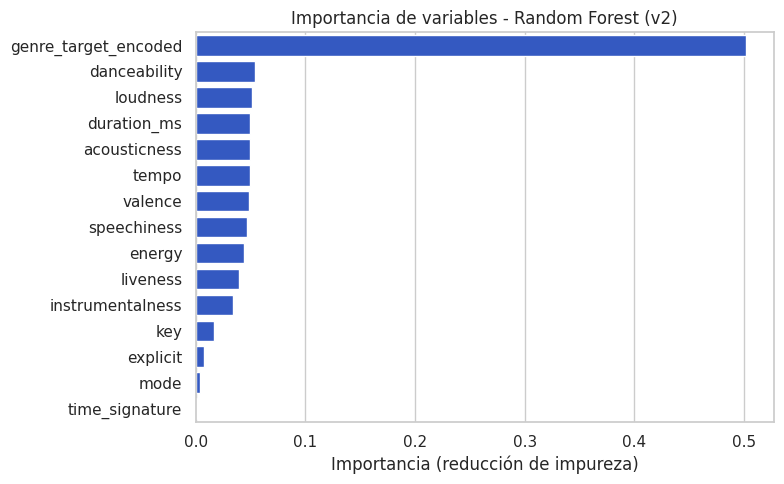

In [12]:
importancias_v2 = pd.Series(rf_v2.feature_importances_, index=X_train_v2.columns).sort_values(ascending=False)
print(importancias_v2.round(4).to_string())

plt.figure(figsize=(8, 5))
sns.barplot(x=importancias_v2.values, y=importancias_v2.index, color="#1D4ED8")
plt.title("Importancia de variables - Random Forest (v2)")
plt.xlabel("Importancia (reducción de impureza)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/importancia_variables.png")
plt.show()

## Evaluación de los KPIs del README

Se miden los tres KPIs del modelo definidos en la sección 3 del README. El umbral de decisión del clasificador se
elige **solo con entrenamiento** (predicciones *out-of-fold* con `GroupKFold`); el conjunto de prueba se usa una
única vez para reportar.

### KPI 1: Error global de predicción (MAE)

Meta: mejorar el MAE en ≥ 20% respecto del baseline (mediana del género).

In [13]:
mae_lr = mean_absolute_error(y_test, pred_lr)
mae_rf = mean_absolute_error(y_test, pred_rf)
for nombre, mae in [("Regresión Lineal (v2)", mae_lr), ("Random Forest (v2)", mae_rf)]:
    mejora = (mae_base - mae) / mae_base * 100
    print(f"{nombre}: MAE {mae:.2f} vs baseline {mae_base:.2f} -> mejora {mejora:+.1f}%  (meta >= 20%: {'CUMPLE' if mejora >= 20 else 'NO CUMPLE'})")

# Diagnóstico: ¿el problema es que el Random Forest minimiza error cuadrático y no absoluto?
hgb_mae = HistGradientBoostingRegressor(loss="absolute_error", max_depth=6, learning_rate=0.05,
                                        max_iter=300, random_state=SEMILLA).fit(X_train_v2, y_train)
mae_hgb = mean_absolute_error(y_test, hgb_mae.predict(X_test_v2))
print(f"\nDiagnóstico: gradient boosting optimizado para MAE -> MAE {mae_hgb:.2f} (baseline {mae_base:.2f})")

Regresión Lineal (v2): MAE 14.08 vs baseline 12.85 -> mejora -9.5%  (meta >= 20%: NO CUMPLE)
Random Forest (v2): MAE 13.64 vs baseline 12.85 -> mejora -6.1%  (meta >= 20%: NO CUMPLE)

Diagnóstico: gradient boosting optimizado para MAE -> MAE 12.84 (baseline 12.85)


### KPI 2: Tasa de detección de hits (Hit Recall)

Meta: identificar ≥ 60% de los hits reales (`popularity > 70`). Para esto se entrena un **clasificador** (Random Forest
con `class_weight="balanced_subsample"`, porque solo ~4% son hits). Se comparan dos umbrales, ambos elegidos solo con
entrenamiento:

1. **Umbral que maximiza F1** (equilibrio entre recall y precisión).
2. **Umbral que alcanza recall ≥ 60%** en entrenamiento (el que exige el KPI).

In [14]:
HIT = 70
yb_train = (y_train > HIT).astype(int).values
yb_test = (y_test > HIT).astype(int).values

def agregar_genero(X_base, g_fit, y_fit, g_aplicar):
    """Target encoding del género calculado con (g_fit, y_fit) y aplicado a g_aplicar."""
    m = y_fit.groupby(g_fit).mean()
    Xn = X_base.drop(columns=COLS_GENERO, errors="ignore").copy()
    Xn["genre_target_encoded"] = g_aplicar.map(m).fillna(y_fit.mean()).values
    return Xn

def nuevo_clasificador():
    return RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20,
                                  class_weight="balanced_subsample", random_state=SEMILLA, n_jobs=-1)

# Probabilidades out-of-fold SOLO dentro de entrenamiento (el género se codifica dentro de cada pliegue)
oof = np.zeros(len(X_train))
for a, b in GroupKFold(n_splits=5).split(X_train, yb_train, groups=grupos_train):
    A_ = agregar_genero(X_train.iloc[a], genero_train.iloc[a], y_train.iloc[a], genero_train.iloc[a])
    B_ = agregar_genero(X_train.iloc[b], genero_train.iloc[a], y_train.iloc[a], genero_train.iloc[b])
    oof[b] = nuevo_clasificador().fit(A_, yb_train[a]).predict_proba(B_)[:, 1]

prec, rec, umbrales = precision_recall_curve(yb_train, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-12)
umbral_f1 = umbrales[f1s[:-1].argmax()]
umbral_r60 = umbrales[np.where(rec[:-1] >= 0.60)[0].max()]
print(f"Umbral F1 (solo train): {umbral_f1:.3f} | umbral recall>=60% (solo train): {umbral_r60:.3f}")

clf = nuevo_clasificador().fit(X_train_v2, yb_train)
proba_test = clf.predict_proba(X_test_v2)[:, 1]

filas = []
for nombre, u in [("Umbral F1", umbral_f1), ("Umbral recall 60% (train)", umbral_r60)]:
    pred = (proba_test >= u).astype(int)
    filas.append({"Umbral": nombre, "Valor": round(u, 3),
                  "Recall hits": round(recall_score(yb_test, pred) * 100, 1),
                  "Precisión": round(precision_score(yb_test, pred) * 100, 1),
                  "% canciones marcadas": round(pred.mean() * 100, 1),
                  "Lift vs azar": round(precision_score(yb_test, pred) / yb_test.mean(), 1)})
tabla_hits = pd.DataFrame(filas)
print(tabla_hits.to_string(index=False))
print(f"\nTasa base de hits en test: {yb_test.mean()*100:.1f}% | ROC-AUC: {roc_auc_score(yb_test, proba_test):.3f} | "
      f"PR-AUC: {average_precision_score(yb_test, proba_test):.3f}")

# Comparación: usar el regresor Random Forest como detector (predicción > 70)
pred_reg_hit = (pred_rf > HIT).astype(int)
print(f"Recall de hits usando el regresor (pred > 70): {recall_score(yb_test, pred_reg_hit)*100:.1f}%")

Umbral F1 (solo train): 0.607 | umbral recall>=60% (solo train): 0.489
                   Umbral  Valor  Recall hits  Precisión  % canciones marcadas  Lift vs azar
                Umbral F1  0.607         34.1       14.5                   9.8           3.5
Umbral recall 60% (train)  0.489         65.2        9.8                  27.8           2.3

Tasa base de hits en test: 4.2% | ROC-AUC: 0.779 | PR-AUC: 0.147
Recall de hits usando el regresor (pred > 70): 0.5%


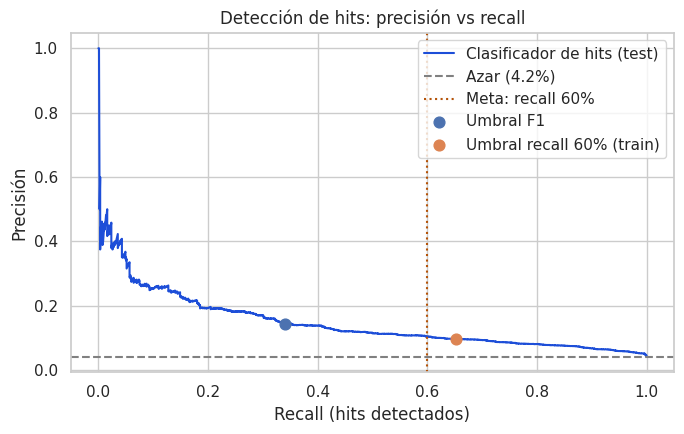

In [15]:
p_t, r_t, _ = precision_recall_curve(yb_test, proba_test)
plt.figure(figsize=(7, 4.5))
plt.plot(r_t, p_t, color="#1D4ED8", label="Clasificador de hits (test)")
plt.axhline(yb_test.mean(), color="gray", linestyle="--", label=f"Azar ({yb_test.mean()*100:.1f}%)")
plt.axvline(0.60, color="#B45309", linestyle=":", label="Meta: recall 60%")
for _, fila in tabla_hits.iterrows():
    plt.scatter(fila["Recall hits"] / 100, fila["Precisión"] / 100, s=60, zorder=3, label=fila["Umbral"])
plt.xlabel("Recall (hits detectados)")
plt.ylabel("Precisión")
plt.title("Detección de hits: precisión vs recall")
plt.legend()
plt.tight_layout()
plt.savefig("../images/curva_precision_recall_hits.png")
plt.show()

### KPI 3: Equidad del error entre géneros

Meta: diferencia ≤ 10 puntos entre el MAE del género mejor predicho y el peor (Random Forest v2, sobre prueba).

Mejor género: iranian (MAE 2.4) | peor: electro (MAE 34.4)
Diferencia: 32.0 puntos (meta <= 10: NO CUMPLE)
Géneros con n < 100 en test: 0 | n mínimo: 147

5 géneros con menor error:
             n  MAE_rf  MAE_base
genero                          
iranian    181     2.4       2.0
sertanejo  200     3.0       2.9
grindcore  177     3.1       2.9
gospel     184     3.1       2.8
comedy     208     3.2       3.2

5 géneros con mayor error:
               n  MAE_rf  MAE_base
genero                            
hip-hop      184    30.5      30.0
alternative  159    31.3      23.1
house        184    33.3      33.7
dance        202    33.8      20.2
electro      217    34.4      35.6

Géneros donde el modelo mejora al baseline: 40 de 114


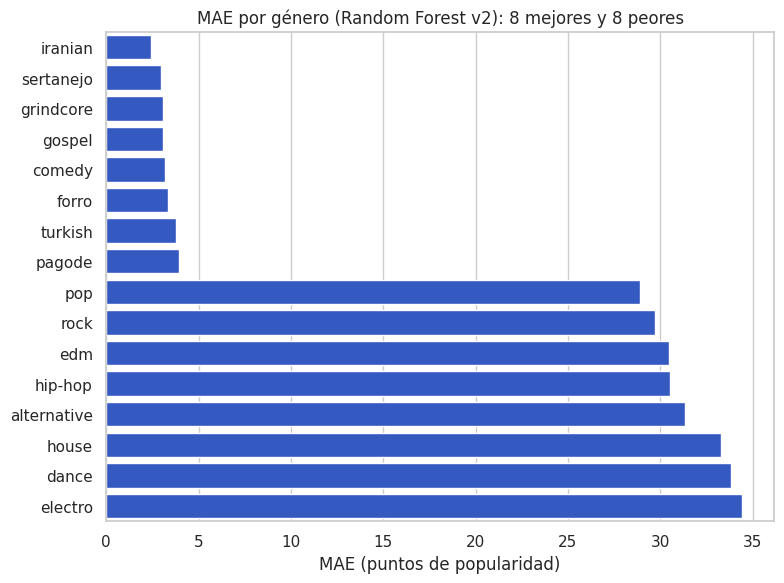

In [16]:
err = pd.DataFrame({"genero": genero_test.values, "real": y_test.values,
                    "rf": pred_rf, "base": pred_baseline.values})
por_genero_mae = (err.assign(e_rf=(err.real - err.rf).abs(), e_base=(err.real - err.base).abs())
                     .groupby("genero").agg(n=("real", "size"), MAE_rf=("e_rf", "mean"), MAE_base=("e_base", "mean"))
                     .sort_values("MAE_rf"))
mejor, peor = por_genero_mae.iloc[0], por_genero_mae.iloc[-1]
dif = por_genero_mae["MAE_rf"].max() - por_genero_mae["MAE_rf"].min()
print(f"Mejor género: {por_genero_mae.index[0]} (MAE {mejor.MAE_rf:.1f}) | peor: {por_genero_mae.index[-1]} (MAE {peor.MAE_rf:.1f})")
print(f"Diferencia: {dif:.1f} puntos (meta <= 10: {'CUMPLE' if dif <= 10 else 'NO CUMPLE'})")
print(f"Géneros con n < 100 en test: {(por_genero_mae['n'] < 100).sum()} | n mínimo: {por_genero_mae['n'].min()}")
print("\n5 géneros con menor error:")
print(por_genero_mae.head(5).round(1).to_string())
print("\n5 géneros con mayor error:")
print(por_genero_mae.tail(5).round(1).to_string())
print(f"\nGéneros donde el modelo mejora al baseline: {(por_genero_mae.MAE_rf < por_genero_mae.MAE_base).sum()} de {len(por_genero_mae)}")

ext = pd.concat([por_genero_mae.head(8), por_genero_mae.tail(8)]).reset_index()
plt.figure(figsize=(8, 6))
sns.barplot(data=ext, x="MAE_rf", y="genero", color="#1D4ED8")
plt.title("MAE por género (Random Forest v2): 8 mejores y 8 peores")
plt.xlabel("MAE (puntos de popularidad)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/error_por_genero.png")
plt.show()

In [17]:
dif_mae = (mae_base - mae_rf) / mae_base * 100
r60 = tabla_hits.iloc[1]
f1r = tabla_hits.iloc[0]
resumen_kpi = pd.DataFrame([
    {"KPI": "MAE vs baseline mediana", "Meta": ">= 20% de mejora", "Resultado": f"{dif_mae:+.1f}%", "Cumple": "Sí" if dif_mae >= 20 else "No"},
    {"KPI": "Hit Recall (umbral F1)", "Meta": ">= 60%", "Resultado": f"{f1r['Recall hits']}% (precisión {f1r['Precisión']}%)", "Cumple": "Sí" if f1r["Recall hits"] >= 60 else "No"},
    {"KPI": "Hit Recall (umbral recall 60% en train)", "Meta": ">= 60%", "Resultado": f"{r60['Recall hits']}% (precisión {r60['Precisión']}%, marca {r60['% canciones marcadas']}% del catálogo)", "Cumple": "Sí" if r60["Recall hits"] >= 60 else "No"},
    {"KPI": "Diferencia de MAE entre géneros", "Meta": "<= 10 puntos", "Resultado": f"{dif:.1f} puntos", "Cumple": "Sí" if dif <= 10 else "No"},
])
print(resumen_kpi.to_string(index=False))

                                    KPI             Meta                                        Resultado Cumple
                MAE vs baseline mediana >= 20% de mejora                                            -6.1%     No
                 Hit Recall (umbral F1)           >= 60%                          34.1% (precisión 14.5%)     No
Hit Recall (umbral recall 60% en train)           >= 60% 65.2% (precisión 9.8%, marca 27.8% del catálogo)     Sí
        Diferencia de MAE entre géneros     <= 10 puntos                                      32.0 puntos     No


### Sensibilidad: anomalías de duración

El README prometía comparar el error con y sin las anomalías documentadas en el EP1. El `tempo = 0` ya quedó fuera
con el filtro de compás; queda la duración extrema (> 8,7 min). Se compara con un modelo rápido
(`HistGradientBoostingRegressor`), evaluando ambos sobre **el mismo** conjunto de prueba completo.

In [18]:
umbral_dur = 522000  # Q3 + 3*IQR calculado en el EP1 (ms)
mascara = (df.iloc[train_idx]["duration_ms"] <= umbral_dur).values
h_con = HistGradientBoostingRegressor(random_state=SEMILLA).fit(X_train_v2, y_train)
h_sin = HistGradientBoostingRegressor(random_state=SEMILLA).fit(X_train_v2[mascara], y_train[mascara])
print(f"Filas de entrenamiento con duración extrema: {(~mascara).sum()}")
print(f"MAE test CON anomalías: {mean_absolute_error(y_test, h_con.predict(X_test_v2)):.3f} | "
      f"SIN anomalías: {mean_absolute_error(y_test, h_sin.predict(X_test_v2)):.3f}")

Filas de entrenamiento con duración extrema: 968
MAE test CON anomalías: 13.966 | SIN anomalías: 13.983


### Comparación: modelo entrenado con y sin los `popularity = 0`

El EDA mostró que el 14% de las canciones tiene `popularity = 0`, concentradas en ciertos géneros, y que al excluirlos la
señal de algunas variables sube. Aquí se prueba qué pasa con el modelo y con el error por género:

- **Entrenado CON ceros:** el Random Forest v2 de arriba.
- **Entrenado SIN ceros:** mismo Random Forest (300 árboles), pero entrenado solo con canciones con `popularity > 0`. El *target
  encoding* del género y el baseline de mediana se recalculan con esas mismas canciones.

Cada uno se evalúa sobre **dos conjuntos de prueba**: el completo (lo que pasaría en la realidad, con ceros) y el de prueba sin
ceros. Cada modelo se compara con **su propio** baseline (mediana del género calculada con sus mismos datos de entrenamiento).

In [19]:
# Escenario SIN ceros: entrenamiento solo con popularity > 0
mask_nz = (y_train > 0).values
y_train_nz = y_train[mask_nz]
genero_train_nz = genero_train[mask_nz]
mapa_nz = y_train_nz.groupby(genero_train_nz).mean()

X_train_nz = X_train.drop(columns=COLS_GENERO)[mask_nz].copy()
X_train_nz["genre_target_encoded"] = genero_train_nz.map(mapa_nz).values
X_test_nz = X_test.drop(columns=COLS_GENERO).copy()
X_test_nz["genre_target_encoded"] = genero_test.map(mapa_nz).fillna(y_train_nz.mean()).values

rf_nz = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=5,
                              random_state=SEMILLA, n_jobs=-1).fit(X_train_nz, y_train_nz)
pred_rf_nz = rf_nz.predict(X_test_nz)
med_nz = y_train_nz.groupby(genero_train_nz).median()
pred_base_nz = genero_test.map(med_nz).fillna(y_train_nz.median()).values

print(f"Entrenamiento: {len(y_train)} filas con ceros | {mask_nz.sum()} sin ceros ({(~mask_nz).mean()*100:.1f}% de ceros retirados)")
print(f"Prueba: {len(y_test)} filas completas | {(y_test > 0).sum()} sin ceros")

Entrenamiento: 89993 filas con ceros | 77485 sin ceros (13.9% de ceros retirados)
Prueba: 22426 filas completas | 19221 sin ceros


In [20]:
escenarios = {
    "Entrenado CON ceros": (pred_rf, pred_baseline.values),
    "Entrenado SIN ceros": (pred_rf_nz, pred_base_nz),
}
evaluaciones = {"Prueba completa (con ceros)": np.ones(len(y_test), dtype=bool),
                "Prueba sin ceros": (y_test > 0).values}

filas, por_genero_ceros = [], {}
for ev, m in evaluaciones.items():
    for esc, (p_mod, p_base) in escenarios.items():
        real = y_test.values[m]
        e = pd.DataFrame({"genero": genero_test.values[m], "e_mod": np.abs(real - p_mod[m]), "e_base": np.abs(real - p_base[m])})
        g = e.groupby("genero").agg(n=("e_mod", "size"), MAE_mod=("e_mod", "mean"), MAE_base=("e_base", "mean"))
        por_genero_ceros[(ev, esc)] = g
        mae_m, mae_b = e["e_mod"].mean(), e["e_base"].mean()
        filas.append({"Evaluación": ev, "Entrenamiento": esc,
                      "MAE modelo": round(mae_m, 2), "MAE baseline": round(mae_b, 2),
                      "Mejora vs baseline (%)": round((mae_b - mae_m) / mae_b * 100, 1),
                      "Mejor género": f"{g.MAE_mod.idxmin()} ({g.MAE_mod.min():.1f})",
                      "Peor género": f"{g.MAE_mod.idxmax()} ({g.MAE_mod.max():.1f})",
                      "Dif. mejor-peor": round(g.MAE_mod.max() - g.MAE_mod.min(), 1),
                      "Géneros que mejoran al baseline": f"{(g.MAE_mod < g.MAE_base).sum()} de {len(g)}"})
comparacion_ceros = pd.DataFrame(filas)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print(comparacion_ceros.to_string(index=False))
print("\nn mínimo por género en la prueba sin ceros:", por_genero_ceros[("Prueba sin ceros", "Entrenado CON ceros")]["n"].min())

                 Evaluación       Entrenamiento  MAE modelo  MAE baseline  Mejora vs baseline (%)  Mejor género    Peor género  Dif. mejor-peor Géneros que mejoran al baseline
Prueba completa (con ceros) Entrenado CON ceros       13.64         12.85                    -6.1 iranian (2.4) electro (34.4)             32.0                       40 de 114
Prueba completa (con ceros) Entrenado SIN ceros       14.54         14.76                     1.4  comedy (3.0)   dance (43.6)             40.6                       58 de 114
           Prueba sin ceros Entrenado CON ceros       11.13         11.01                    -1.1  brazil (2.8)   dance (38.2)             35.4                       42 de 114
           Prueba sin ceros Entrenado SIN ceros       10.11         10.11                     0.0  brazil (2.9)   dance (38.4)             35.5                       51 de 114

n mínimo por género en la prueba sin ceros: 60


Géneros que más MEJORAN sin ceros (cambio negativo):
                   cambio MAE  % ceros del género
genero                                           
british                  -2.4                13.0
progressive-house        -1.8                10.0
alt-rock                 -1.6                35.0
ambient                  -1.4                 7.0
metal                    -1.4                21.0

Géneros que más EMPEORAN sin ceros:
         cambio MAE  % ceros del género
genero                                 
latin           8.6                59.0
dance           9.7                48.0
country        10.7                59.0
soul           12.9                61.0
jazz           13.3                68.0

Correlación entre % de ceros del género y cambio de MAE: 0.78


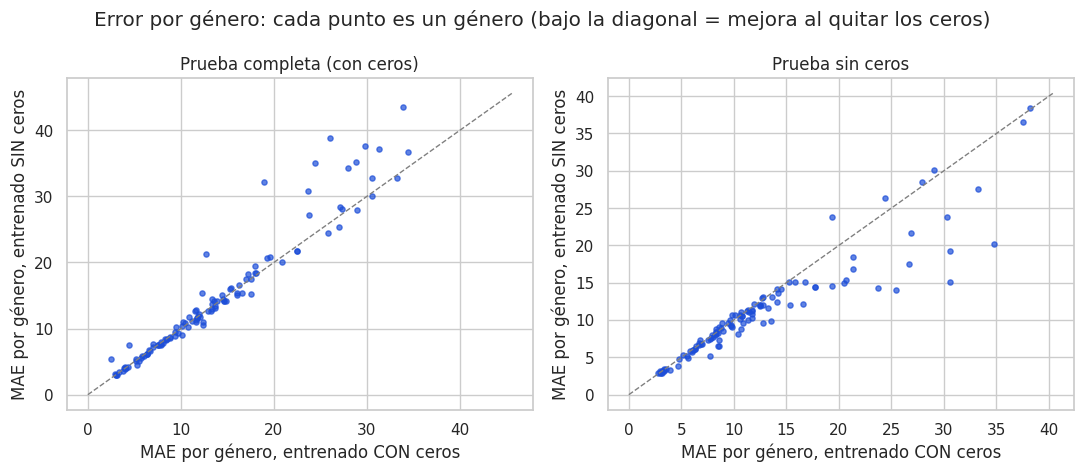

In [21]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.8))
for eje, ev in zip(ejes, evaluaciones):
    a = por_genero_ceros[(ev, "Entrenado CON ceros")]["MAE_mod"]
    b = por_genero_ceros[(ev, "Entrenado SIN ceros")]["MAE_mod"]
    eje.scatter(a, b, s=14, alpha=0.7, color="#1D4ED8")
    lim = max(a.max(), b.max()) + 2
    eje.plot([0, lim], [0, lim], color="gray", linestyle="--", linewidth=1)
    eje.set_title(ev); eje.set_xlabel("MAE por género, entrenado CON ceros"); eje.set_ylabel("MAE por género, entrenado SIN ceros")
plt.suptitle("Error por género: cada punto es un género (bajo la diagonal = mejora al quitar los ceros)")
plt.tight_layout()
plt.savefig("../images/ceros_error_por_genero.png")
plt.show()

# Géneros que más cambian al entrenar sin ceros (evaluados en la prueba completa)
cambio = (por_genero_ceros[("Prueba completa (con ceros)", "Entrenado SIN ceros")]["MAE_mod"]
          - por_genero_ceros[("Prueba completa (con ceros)", "Entrenado CON ceros")]["MAE_mod"]).sort_values()
pct_ceros_gen = df.groupby("track_genre_label")[TARGET].apply(lambda s: (s == 0).mean() * 100)
tabla_cambio = pd.DataFrame({"cambio MAE": cambio.round(1), "% ceros del género": pct_ceros_gen.reindex(cambio.index).round(0)})
print("Géneros que más MEJORAN sin ceros (cambio negativo):"); print(tabla_cambio.head(5).to_string())
print("\nGéneros que más EMPEORAN sin ceros:"); print(tabla_cambio.tail(5).to_string())
print(f"\nCorrelación entre % de ceros del género y cambio de MAE: {tabla_cambio.corr().iloc[0, 1]:.2f}")

**Lectura de la comparación con y sin ceros**

| Entrenamiento | Evaluación | MAE modelo | MAE baseline | Mejora | Dif. mejor-peor género | Géneros que mejoran al baseline |
| :--- | :--- | :-: | :-: | :-: | :-: | :-: |
| Con ceros | Prueba completa | 13,64 | 12,85 | −6,1% | 32,0 | 40 de 114 |
| Sin ceros | Prueba completa | 14,54 | 14,76 | +1,4% | 40,6 | 58 de 114 |
| Con ceros | Prueba sin ceros | 11,13 | 11,01 | −1,1% | 35,4 | 42 de 114 |
| Sin ceros | Prueba sin ceros | 10,11 | 10,11 | 0,0% | 35,5 | 51 de 114 |

1. **En condiciones reales (prueba completa), entrenar sin ceros empeora el error:** MAE 14,54 vs 13,64 y la diferencia entre
   el mejor y el peor género sube de 32,0 a 40,6 puntos. El modelo sin ceros «mejora» 1,4% a *su* baseline, pero ese baseline
   (14,76) es peor que la mediana del género calculada con ceros (12,85), que sigue siendo el mejor predictor.
2. **Los ceros no son ruido al azar:** se concentran en ciertos géneros. Al quitarlos del entrenamiento, los géneros con
   muchos ceros empeoran mucho en la prueba completa (`jazz` +13,3 de MAE con 68% de ceros, `soul` +12,9, `country` +10,7,
   `latin` +8,6), porque el modelo nunca aprende que en esos géneros lo normal es 0. Entre el % de ceros de un género y el
   cambio de MAE la correlación es 0,78. Los géneros con pocos ceros mejoran levemente (hasta −2,4 en `british`).
3. **Evaluando solo canciones con popularidad > 0, el modelo sin ceros tiene un MAE más bajo (10,11 vs 11,13), pero queda
   exactamente igual a su baseline (0,0%).** Incluso sin ceros, el audio no mejora la regla de mediana por género: la
   conclusión principal se mantiene y el error «bajo» no es mérito del modelo, sino de una prueba más fácil.
4. **Quitar los ceros no arregla la equidad entre géneros:** la diferencia sigue en ~35 puntos en la prueba sin ceros y `dance`
   es el peor género en tres de las cuatro combinaciones. El KPI de ≤ 10 puntos no se cumple en ninguna.
5. **Decisión:** se mantiene el entrenamiento **con** ceros, que es lo que ocurre en producción, y se recomienda reportar el
   error también sin ellos. Falta aclarar con el negocio qué significa `popularity = 0` (canción sin reproducciones recientes o
   dato faltante); de eso depende si deben tratarse como una clase aparte.

## Aprendizaje no supervisado: segmentación de canciones con K-Means

**Para qué sirve en el negocio.** El problema es decidir qué canciones incluir en playlists y campañas. Un clustering
permite agrupar el catálogo en **perfiles sonoros** (sin usar `popularity` ni el género) y luego ver qué perfiles
concentran más hits, de modo que el equipo de programación pueda diseñar playlists por perfil y priorizar campañas.
`popularity` se usa **solo después** del clustering, para interpretar los grupos.

**Datos del clustering:**

- Una fila por **canción distinta** (artista + nombre): si no, una canción repetida en 5 géneros pesaría 5 veces.
- Sin `tempo = 0` (ruido blanco, audio corrupto).
- Variables: las 9 de audio más la **duración en logaritmo** (la duración tiene cola larga de hasta 87 min) y todas **estandarizadas**
  (`StandardScaler`), porque K-Means usa distancias y `loudness` (dB) o `tempo` (BPM) dominarían a las variables 0-1.
- Los valores se leen en sus **unidades originales** desde el CSV crudo para poder interpretar los perfiles (BPM, dB, minutos).

In [22]:
raw = pd.read_csv("../data/Spotify_Tracks_Dataset.csv")
raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")]).drop_duplicates(subset=["track_id", "track_genre"])

cl = df[["track_id", "grupo_cancion", "artists", "track_name", "track_genre_label", "popularity"]].merge(
    raw[["track_id", "track_genre", "duration_ms"] + audio_cols],
    left_on=["track_id", "track_genre_label"], right_on=["track_id", "track_genre"], how="left")
assert len(cl) == len(df) and cl[audio_cols].isna().sum().sum() == 0, "El cruce con el CSV crudo perdió filas"

n0 = len(cl)
cl = cl[cl["tempo"] > 0]
print("Filas con tempo = 0 retiradas aquí:", n0 - len(cl))
cl = cl.drop_duplicates("grupo_cancion").reset_index(drop=True)
print("Canciones distintas para el clustering:", len(cl))

X_cl = cl[audio_cols].copy()
X_cl["log_duracion"] = np.log(cl["duration_ms"])
scaler_km = StandardScaler()
Z = scaler_km.fit_transform(X_cl)
print("Variables:", list(X_cl.columns))

Filas con tempo = 0 retiradas aquí: 0
Canciones distintas para el clustering: 80286
Variables: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'log_duracion']


### Elección de k

Se evalúan k = 2 a 10 con tres criterios: **codo** (inercia), **coeficiente de silueta** (cohesión/separación, de -1
a 1) e **índice de Davies-Bouldin** (menor es mejor). La silueta se calcula sobre una muestra de 10.000 canciones.

 k    inercia  silueta  davies_bouldin
 2 647316.417    0.240           1.695
 3 580055.375    0.149           2.023
 4 529408.439    0.153           1.815
 5 486810.483    0.157           1.750
 6 448826.025    0.170           1.576
 7 414445.828    0.174           1.524
 8 395305.306    0.156           1.532
 9 378469.287    0.160           1.525
10 365029.312    0.150           1.581


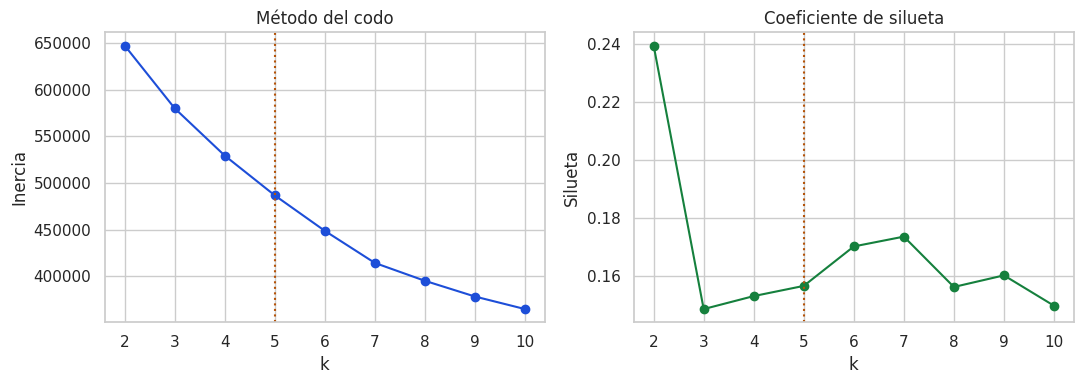

In [23]:
ks = range(2, 11)
filas = []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
    filas.append({"k": k, "inercia": km_k.inertia_,
                  "silueta": silhouette_score(Z, km_k.labels_, sample_size=10000, random_state=SEMILLA),
                  "davies_bouldin": davies_bouldin_score(Z, km_k.labels_)})
eval_k = pd.DataFrame(filas)
print(eval_k.round(3).to_string(index=False))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(eval_k["k"], eval_k["inercia"], marker="o", color="#1D4ED8")
ejes[0].axvline(5, color="#B45309", linestyle=":")
ejes[0].set_title("Método del codo"); ejes[0].set_xlabel("k"); ejes[0].set_ylabel("Inercia")
ejes[1].plot(eval_k["k"], eval_k["silueta"], marker="o", color="#15803D")
ejes[1].axvline(5, color="#B45309", linestyle=":")
ejes[1].set_title("Coeficiente de silueta"); ejes[1].set_xlabel("k"); ejes[1].set_ylabel("Silueta")
plt.tight_layout()
plt.savefig("../images/kmeans_codo_silueta.png")
plt.show()

**Lectura de la elección de k**

- La silueta es máxima en **k = 2** (0,24), pero esa solución solo separa «suave» de «intenso» y es demasiado gruesa para armar
  playlists. Desde k = 3 la silueta queda entre 0,15 y 0,17 sin un máximo claro (el mayor es k = 7, con 0,174), y la inercia
  baja de forma gradual, sin un codo marcado. Davies-Bouldin mejora solo levemente a partir de k = 6.
- Los criterios estadísticos, entonces, **no apuntan a un único k**. Se elige **k = 5** por criterio de negocio e
  interpretabilidad: da perfiles sonoros distintos entre sí, cada uno con al menos ~8% del catálogo, y un número manejable
  de playlists o campañas. Pasar a k = 6 o 7 mejora la silueta apenas 0,01-0,02, una ganancia que no justifica más perfiles.
- **Advertencia para la defensa:** la silueta de k = 5 es baja (≈ 0,16). Los atributos de audio forman un continuo y no
  «islas» bien separadas, así que los grupos se solapan en sus bordes. Los grupos son una **segmentación útil**, no
  categorías naturales. Lo que sí es sólido es su estabilidad: con otras semillas se obtienen los mismos grupos (ARI ≥ 0,99).

In [24]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(Z)
cl["cluster"] = kmeans.labels_
sil_k = silhouette_score(Z, kmeans.labels_, sample_size=10000, random_state=SEMILLA)

# Estabilidad: ¿se obtienen los mismos grupos con otras semillas?
aris = [adjusted_rand_score(kmeans.labels_, KMeans(n_clusters=K, n_init=10, random_state=s).fit(Z).labels_) for s in (1, 7, 99)]
print(f"Silueta (k={K}): {sil_k:.3f} | ARI entre semillas: {np.round(aris, 3)}")

perfil = X_cl.assign(cluster=cl["cluster"]).groupby("cluster").mean()
perfil["duracion_min"] = np.exp(perfil["log_duracion"]) / 60000
perfil = perfil.drop(columns="log_duracion")
perfil["n_canciones"] = cl.groupby("cluster").size()
perfil["% catálogo"] = perfil["n_canciones"] / len(cl) * 100
perfil["popularidad_media"] = cl.groupby("cluster")["popularity"].mean()
perfil["% hits"] = cl.groupby("cluster")["popularity"].apply(lambda s: (s > 70).mean() * 100)

# Nombres por reglas sobre el perfil (no dependen del número que K-Means asigne a cada grupo)
nombres = {}
restantes = set(perfil.index)
def asignar(nombre, serie):
    c = serie[list(restantes)].idxmax(); nombres[c] = nombre; restantes.discard(c)
asignar("Acústico e instrumental", perfil["instrumentalness"] + perfil["acousticness"] - perfil["energy"])
asignar("En vivo / hablado", perfil["liveness"] + perfil["speechiness"])
asignar("Bailable y alegre", perfil["danceability"] + perfil["valence"])
asignar("Energético e intenso", perfil["energy"] - perfil["acousticness"])
for c in restantes:
    nombres[c] = "Acústico moderado"
cl["perfil"] = cl["cluster"].map(nombres)
perfil.insert(0, "perfil", perfil.index.map(nombres))

pd.set_option("display.width", 250)
print(perfil.round(2).sort_values("% hits", ascending=False).to_string())
print(f"\nTasa de hits global (canciones distintas): {(cl['popularity'] > 70).mean()*100:.1f}%")

Silueta (k=5): 0.157 | ARI entre semillas: [0.999 0.993 0.993]
                          perfil  danceability  energy  loudness  speechiness  acousticness  instrumentalness  liveness  valence   tempo  duracion_min  n_canciones  % catálogo  popularidad_media  % hits
cluster                                                                                                                                                                                                   
2              Bailable y alegre          0.69    0.73     -6.51         0.10          0.20              0.06      0.17     0.70  121.82          3.36        27554       34.32              36.25    4.58
3              Acústico moderado          0.54    0.39    -10.55         0.06          0.67              0.07      0.16     0.40  113.68          3.38        17159       21.37              36.04    2.84
4           Energético e intenso          0.49    0.81     -6.21         0.08          0.06              0.28      0.19     0

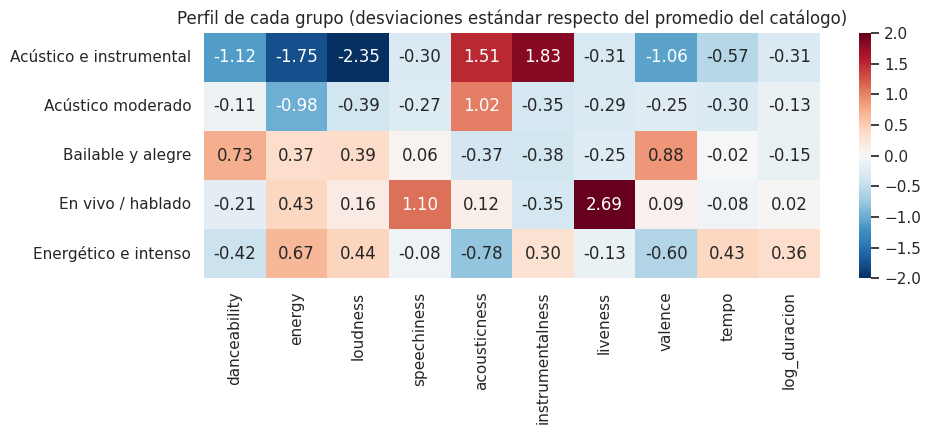

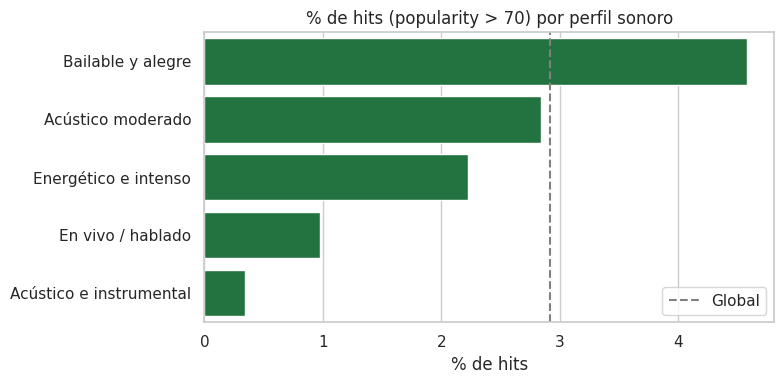

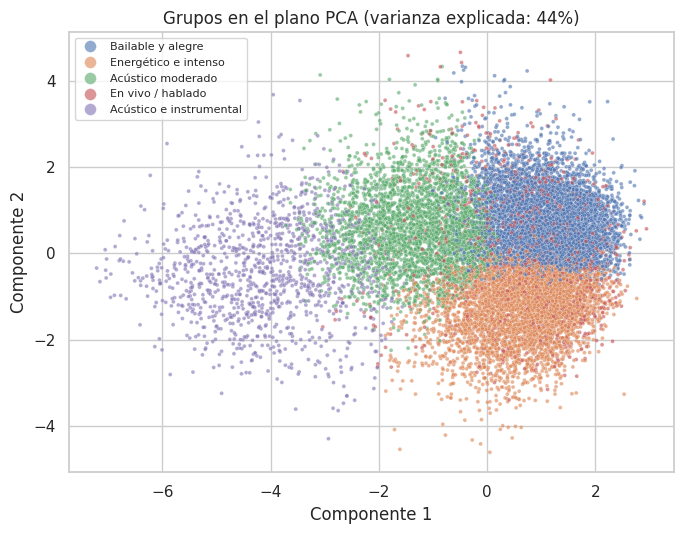

In [25]:
cols_z = list(X_cl.columns)
z_perfil = pd.DataFrame(Z, columns=cols_z).groupby(cl["perfil"].values).mean()
plt.figure(figsize=(10, 4.5))
sns.heatmap(z_perfil, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-2, vmax=2)
plt.title("Perfil de cada grupo (desviaciones estándar respecto del promedio del catálogo)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/kmeans_perfiles.png")
plt.show()

orden = perfil.sort_values("% hits", ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(x=orden["% hits"].values, y=orden["perfil"].values, color="#15803D")
plt.axvline((cl["popularity"] > 70).mean() * 100, color="gray", linestyle="--", label="Global")
plt.title("% de hits (popularity > 70) por perfil sonoro")
plt.xlabel("% de hits"); plt.ylabel(""); plt.legend()
plt.tight_layout()
plt.savefig("../images/kmeans_hits_por_perfil.png")
plt.show()

muestra = np.random.RandomState(SEMILLA).choice(len(Z), 15000, replace=False)
pca = PCA(n_components=2, random_state=SEMILLA).fit(Z)
P = pca.transform(Z[muestra])
plt.figure(figsize=(7, 5.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=cl["perfil"].values[muestra], s=8, alpha=0.6)
plt.title(f"Grupos en el plano PCA (varianza explicada: {pca.explained_variance_ratio_.sum()*100:.0f}%)")
plt.xlabel("Componente 1"); plt.ylabel("Componente 2")
plt.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.savefig("../images/kmeans_pca.png")
plt.show()

In [26]:
# ¿Cuánta de la variación de popularity explican los perfiles sonoros, comparado con el género?
def eta2(datos, col):
    media = datos["popularity"].mean()
    ss_entre = sum(len(g) * (g["popularity"].mean() - media) ** 2 for _, g in datos.groupby(col))
    return ss_entre / ((datos["popularity"] - media) ** 2).sum()

print(f"η² perfil sonoro -> popularity: {eta2(cl, 'perfil'):.3f}")
print(f"η² género -> popularity (mismas canciones): {eta2(cl, 'track_genre_label'):.3f}")

# Géneros más frecuentes en cada perfil (cada canción cuenta en su primer género listado)
tabla_gen = cl.groupby("perfil")["track_genre_label"].agg(lambda s: ", ".join(s.value_counts().head(4).index))
print("\nGéneros más frecuentes por perfil:")
print(tabla_gen.to_string())

η² perfil sonoro -> popularity: 0.011
η² género -> popularity (mismas canciones): 0.379

Géneros más frecuentes por perfil:
perfil
Acústico e instrumental                   new-age, ambient, sleep, classical
Acústico moderado                       tango, cantopop, honky-tonk, romance
Bailable y alegre                              kids, salsa, forro, dancehall
En vivo / hablado                           comedy, pagode, sertanejo, samba
Energético e intenso       black-metal, grindcore, death-metal, drum-and-...


### Comparación de algoritmos de clustering

Para justificar la elección de K-Means se comparan tres algoritmos con **k = 5** sobre la misma matriz estandarizada `Z`, usando una muestra aleatoria de 8.000 canciones (el clustering jerárquico necesita la matriz de distancias completa y no escala a 80.000 filas):

- **K-Means** (el elegido).
- **Jerárquico aglomerativo (Ward):** alternativa determinística que no depende de la inicialización.
- **Gaussian Mixture:** permite grupos elípticos y asignación probabilística.

Se miden silueta, Davies-Bouldin, Calinski-Harabasz, tamaño del grupo más chico y más grande, acuerdo con K-Means (ARI) y cuánta variación de `popularity` explican los grupos (η²). **DBSCAN** no se probó: busca zonas densas separadas por huecos, y la silueta baja de K-Means indica que los atributos forman un continuo sin «islas» claras.

In [27]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import calinski_harabasz_score

# Muestra de 8.000 canciones: el clustering jerárquico necesita la matriz de distancias completa (memoria O(n²))
idx = np.random.RandomState(SEMILLA).choice(len(Z), 8000, replace=False)
Zs = Z[idx]
algoritmos = {
    "K-Means (k=5)": KMeans(n_clusters=5, n_init=10, random_state=SEMILLA),
    "Jerárquico Ward (k=5)": AgglomerativeClustering(n_clusters=5, linkage="ward"),
    "Gaussian Mixture (5 comp.)": GaussianMixture(n_components=5, covariance_type="full", n_init=3, random_state=SEMILLA),
}
etiquetas = {nombre: alg.fit_predict(Zs) for nombre, alg in algoritmos.items()}
ref = etiquetas["K-Means (k=5)"]

filas = []
for nombre, lab in etiquetas.items():
    tam = np.bincount(lab) / len(lab) * 100
    tmp = cl.iloc[idx].assign(grupo_alt=lab)
    filas.append({"Algoritmo": nombre,
                  "Silueta": silhouette_score(Zs, lab),
                  "Davies-Bouldin (menor es mejor)": davies_bouldin_score(Zs, lab),
                  "Calinski-Harabasz": calinski_harabasz_score(Zs, lab),
                  "Grupo más chico (%)": tam.min(),
                  "Grupo más grande (%)": tam.max(),
                  "ARI vs K-Means": adjusted_rand_score(ref, lab),
                  "η² popularity": eta2(tmp, "grupo_alt")})
comparacion = pd.DataFrame(filas)
print(comparacion.round(3).to_string(index=False))

                 Algoritmo  Silueta  Davies-Bouldin (menor es mejor)  Calinski-Harabasz  Grupo más chico (%)  Grupo más grande (%)  ARI vs K-Means  η² popularity
             K-Means (k=5)    0.159                            1.724           1303.673                7.638                34.613           1.000          0.010
     Jerárquico Ward (k=5)    0.185                            1.557           1093.766                1.225                59.800           0.289          0.028
Gaussian Mixture (5 comp.)    0.031                            3.394            470.274                9.450                35.875           0.142          0.038


**Lectura de la comparación**

- **K-Means** tiene el mejor índice de Calinski-Harabasz (1.304) y grupos equilibrados (entre 8% y 35% del catálogo). Además es estable entre semillas (ARI ≥ 0,99, ver arriba).
- **Ward** logra la silueta más alta (0,185), pero esa ventaja no se traduce en grupos útiles: deja **60% de las canciones en un solo grupo** y uno de apenas 1,2%, inservible para armar playlists. Su acuerdo con K-Means es bajo (ARI 0,29), es decir, propone otra partición.
- **Gaussian Mixture** es el peor en las métricas internas (silueta 0,03; Davies-Bouldin 3,39): los grupos se solapan casi por completo (ARI 0,14 vs K-Means).
- **Ningún algoritmo explica la popularidad:** η² ≤ 0,04 en los tres, frente a 0,38 del género. Es el mismo hallazgo que con K-Means, así que la elección del algoritmo no cambia la conclusión de negocio.
- **Decisión:** se mantiene K-Means por equilibrio de tamaños, estabilidad e interpretabilidad. Limitación: la comparación usa una muestra de 8.000 canciones y un solo valor de k.

### Interpretación de los perfiles sonoros (k = 5)

| Perfil | Cómo suena | % del catálogo | % hits |
| :--- | :--- | :-: | :-: |
| **Bailable y alegre** | Alta bailabilidad (0,69) y valencia (0,70), energía alta, poca acústica | 34,3% | **4,6%** |
| **Acústico moderado** | Energía media-baja (0,39), acústico (0,67), ~114 BPM | 21,4% | 2,8% |
| **Energético e intenso** | Energía 0,81, casi sin acústica, ~135 BPM, más largo (4,1 min), algo instrumental | 28,5% | 2,2% |
| **En vivo / hablado** | Liveness 0,75 y speechiness 0,21 (altos): grabaciones en vivo, humor, hablado | 7,8% | 1,0% |
| **Acústico e instrumental** | Muy suave (-20,8 dB), instrumentalness 0,78, acousticness 0,84 | 8,0% | 0,3% |

La tasa global de hits entre canciones distintas es 2,9%. **Bailable y alegre** la supera en ~1,6 veces y
**Acústico e instrumental** queda en una décima parte.

**Qué patrón relevante muestra y qué no:**

- Los perfiles se alinean con el género (por ejemplo, el perfil acústico e instrumental agrupa `new-age`, `ambient`, `sleep`
  y `classical`; el en vivo / hablado incluye `comedy`). Es coherente con que el género sea la señal dominante.
- **El perfil sonoro explica muy poco de la popularidad:** η² = 0,011, frente a 0,379 del género sobre las mismas
  canciones. Los perfiles sirven para **organizar el catálogo**, no para predecir qué canción será un hit.

**Uso en el negocio:**

- **Playlists por perfil:** cada grupo corresponde a un contexto de uso distinto (bailar / fiesta, estudio o relajo,
  entrenamiento, etc.), lo que ordena la programación sin depender de criterios subjetivos.
- **Campañas:** el perfil «Bailable y alegre» concentra más hits y es el candidato natural para campañas de difusión;
  los perfiles «Acústico e instrumental» y «En vivo / hablado» rara vez generan hits y conviene tratarlos como nichos
  (playlists de contexto) y no medir su éxito con la misma vara.
- **Cuidado:** que un perfil tenga más hits no significa que sonar así cause la popularidad; esa diferencia está
  mezclada con el género y con la exposición que recibe cada tipo de música.

## Interpretación de resultados y recomendaciones

### Resumen de KPIs

| KPI | Meta | Resultado | ¿Cumple? |
| :--- | :--- | :--- | :-: |
| MAE vs baseline (mediana del género) | ≥ 20% de mejora | **-6,1%** (RF: 13,64 vs 12,85) | No |
| Hit Recall, umbral F1 | ≥ 60% | 34,1% (precisión 14,5%) | No |
| Hit Recall, umbral calibrado en train para recall 60% | ≥ 60% | 65,2% (precisión 9,8%; marca 27,8% del catálogo) | Sí, a costa de precisión |
| Diferencia de MAE entre géneros | ≤ 10 puntos | 32,0 puntos (`iranian` 2,4 vs `electro` 34,4) | No |

### Qué significan los resultados

1. **El género domina y el audio aporta poco.** La variable más importante del Random Forest es el género codificado (~50% de la
   importancia); las 9 de audio se reparten el resto casi por igual (3-5% cada una), señal de que ninguna aporta una
   relación fuerte. Coincide con el EDA (|r| ≤ 0,10 con la popularidad).
2. **El modelo de regresión no supera una regla simple.** Con la partición corregida y el baseline justo, el Random Forest
   tiene un MAE (13,64) **peor** que predecir la mediana del género (12,85). Mejora el RMSE (18,91 vs 20,65 de la mediana y
   19,25 de la media) porque minimiza error cuadrático, pero esa ganancia es modesta. Un gradient boosting optimizado
   directamente para MAE llega a 12,84, es decir, **empata** con el baseline: el problema no es la función de pérdida,
   sino que el audio no agrega información sobre el género. Además el Random Forest sobreajusta (MAE 10,46 en train vs
   13,64 en test); la Regresión Lineal no, pero tampoco mejora.
3. **Lo más útil es el clasificador de hits.** Con ROC-AUC 0,78 y PR-AUC 0,147 (3,5 veces la tasa base de 4,2%) ordena las
   canciones bastante mejor que el azar. Usar el regresor como detector es inútil (solo encuentra 0,5% de los hits, porque
   sus predicciones se concentran cerca del promedio). Pero hay un **trade-off inevitable**: con umbral de F1 detecta 34% de los hits
   con 14,5% de precisión; para cumplir la meta de 60% de recall hay que marcar 28% del catálogo y solo ~1 de cada 10
   canciones marcadas es un hit (2,3 veces el azar).
4. **El error no es parejo entre géneros.** El modelo mejora al baseline en solo 40 de 114 géneros y empeora mucho en
   algunos (`dance` 33,8 vs 20,2; `alternative` 31,3 vs 23,1). Los géneros con error bajo (`iranian`, `sertanejo`, `grindcore`, `gospel`) son aquellos donde casi todas
   las canciones tienen una popularidad parecida (desviación estándar de 4 a 5 puntos), así que son «fáciles» para cualquier
   método; los de error alto (`electro`, `dance`, `house`, `hip-hop`, `alternative`) mezclan canciones muy populares con
   muchos ceros (desviación de 33 a 35 puntos y 30-48% de ceros). Esto confirma el riesgo ético ya descrito: el
   modelo no debe usarse igual en todos los géneros.
5. **Decisiones metodológicas que no cambian la conclusión:** conservar las duraciones extremas o no da el mismo error
   (13,97 vs 13,98) y el target encoding calculado fuera de muestra da un MAE apenas peor (13,78 vs 13,62), es
   decir, el encoding con todo el train es levemente optimista, pero no explica nada. Entrenar sin los ceros **empeora** el
   error real (14,54 vs 13,64) y no corrige la equidad entre géneros (ver la comparación con y sin ceros).

### Recomendaciones para el negocio

- **No usar el modelo para predecir la popularidad exacta** de una canción: como referencia, el promedio histórico (la mediana)
  del género es igual o mejor.
- **Usar el clasificador como filtro previo (shortlist) para campañas**, no como decisión final: el umbral se fija según la
  capacidad de la campaña (más recall = más canciones a revisar y menor precisión) y la decisión final la toma un
  equipo humano.
- **Organizar playlists y campañas por perfil sonoro** (K-Means), sabiendo que los perfiles ordenan el catálogo pero casi no
  predicen popularidad.
- **Incorporar datos que sí expliquen la popularidad:** seguidores o popularidad del artista, fecha de lanzamiento,
  presencia en playlists. El audio por sí solo no alcanza.
- **Reportar el error por género** y evitar usar el modelo en los géneros donde pierde contra el baseline.

### Limitaciones

La popularidad es una foto en un momento y depende de las reproducciones recientes; el dataset está balanceado por género por
diseño (no refleja el catálogo real); el 14% de ceros ensucia la variable objetivo; y los nombres de artistas son datos
públicos que no deben usarse para decisiones individuales automatizadas.

## Guardado de modelos y resultados

In [28]:
import os
os.makedirs("../models", exist_ok=True)
joblib.dump(scaler, "../models/minmax_audio.joblib")
joblib.dump(mapa_genero, "../models/target_encoding_genero.joblib")
joblib.dump(lr_v2, "../models/regresion_lineal_v2.joblib")
joblib.dump(rf_v2, "../models/random_forest_regresor_v2.joblib", compress=3)
joblib.dump(clf, "../models/random_forest_clasificador_hits.joblib", compress=3)
joblib.dump(scaler_km, "../models/kmeans_standard_scaler.joblib")
joblib.dump(kmeans, "../models/kmeans_k5.joblib")

with open("../models/parametros.json", "w", encoding="utf-8") as f:
    json.dump({"semilla": SEMILLA, "umbral_hit_popularity": HIT,
               "umbral_clasificador_F1": float(umbral_f1), "umbral_clasificador_recall60_train": float(umbral_r60),
               "features_modelo": list(X_train_v2.columns), "features_kmeans": list(X_cl.columns),
               "k_kmeans": K, "nombres_clusters": {int(k): v for k, v in nombres.items()},
               "clave_particion": "artista + nombre (minúsculas)"}, f, ensure_ascii=False, indent=2)

cl[["track_id", "artists", "track_name", "track_genre_label", "popularity", "cluster", "perfil"]].to_csv(
    "../data_procesado/spotify_tracks_clusters.csv", index=False)
print("Modelos guardados:")
for a in sorted(f for f in os.listdir("../models") if f.endswith((".joblib", ".json"))):
    print(f"  {a}: {os.path.getsize('../models/' + a) / 1e6:.1f} MB")

Modelos guardados:
  kmeans_k5.joblib: 0.3 MB
  kmeans_standard_scaler.joblib: 0.0 MB
  minmax_audio.joblib: 0.0 MB
  parametros.json: 0.0 MB
  random_forest_clasificador_hits.joblib: 3.7 MB
  random_forest_regresor_v2.joblib: 37.1 MB
  regresion_lineal_v2.joblib: 0.0 MB
  target_encoding_genero.joblib: 0.0 MB
